<a href="https://colab.research.google.com/github/FabsRobles/Practica2-IA/blob/main/notebook/Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 1. Comprensión del dominio del dataset.

En esta primera parte se hizo un análisis de los datos que aparecen en nuestro dataset, se identificaron tipos de datos, valores y celdas vacías.

In [13]:
import pandas as pd

url="https://raw.githubusercontent.com/FabsRobles/Practica2-IA/refs/heads/main/train.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Teniendo la tabla de valores ahora inspeccionamos los tipos de datos con los que contamos, qué contiene cáda columna y sus valores importantes.

### 1. ¿Cuál es el nombre de las columnas?

In [14]:
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

### 2. ¿Qué representa cada columna?

In [15]:
datos={
    'Columna': ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
    'Descripción': ['Identificador único del pasajero', 'Indica si el pasajero sobrevivió (1) o no (0)', 'Clase del boleto: Primera, Segunda o Tercera0', 'Nombre del pasajero', 'Sexo(male/female)', 'Edad en años', 'Cuántos hermanos o espos@ iban abordo', 'Cuántos padres o hijos iban abordo', 'Número de boleto', 'Lo que pagó por el boleto', 'Número de camarote', 'Puerto donde abordó: C,Q o S'],
    'Tipo de dato': ['Entero', 'Entero', 'Entero', 'Texto', 'Texto', 'Flotante', 'Entero', 'Entero', 'Texto', 'Flotante', 'Texto', 'Texto']
}

df=pd.DataFrame(datos)

df

,Columna,Descripción,Tipo de dato
0,PassengerId,Identificador único del pasajero,Entero
1,Survived,Indica si el pasajero sobrevivió (1) o no (0),Entero
2,Pclass,"Clase del boleto: Primera, Segunda o Tercera0",Entero
3,Name,Nombre del pasajero,Texto
4,Sex,Sexo(male/female),Texto
5,Age,Edad en años,Flotante
6,SibSp,Cuántos hermanos o espos@ iban abordo,Entero
7,Parch,Cuántos padres o hijos iban abordo,Entero
8,Ticket,Número de boleto,Texto
9,Fare,Lo que pagó por el boleto,Flotante


### 3. ¿Cuántos datos faltantes hay en cada columna?

In [29]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


### 4. ¿Hay filas repetidas?

In [17]:
df.duplicated().sum()

np.int64(0)

Después de inspeccionar en qué condiciones se encuentra nuestro dataset, respondemos a las siguientes preguntas.

*   ¿Qué representa cada fila?
> Cada fila de nuestro dataset representa a un pasajero del Titanic.

*   ¿La variable objetivo estaría disponible en un escenario real?
> No, ya que la unica forma de saber si alguien sobrevivió es después del hundimiento, no antes.


*   ¿Existen identificadores o variables con fuga de información?
> La variable Survived contiene la información que requerimos para el análisis, sin embargo en un caso real, esa variable solo estará llena después del hundimiento del barco.


*   ¿Qué decisiones podrían afectar de forma desigual a distintos grupos?
> Si un modelo usara las variables Sex, Age, Pclass, podría favorecer o perjudicar a mujeres, niños o personas de clase baja.







# Actividad 2. Data Profiling

Antes de comenzar dividimos las columnas en grupos de la siguiente manera.

In [18]:
col_num=["Age", "SibSp", "Parch", "Fare"]
col_cat=["Survived", "Pclass", "Sex", "Embarked", "Cabin"]
col_id= ["PassengerId", "Name", "Ticket"]

Lo dividimos de esta forma ya que a pesar de que las variables como "Survived" y "Pclass" parecen números son categorías, ya que no las podemos promediar, mientras que "PassengerId", "Name", "Ticket" no se repiten lo suficiente para considerarlas una categoría.

### Parte 1. Tipo de dato, valores válidos y ausentes

In [21]:
def validos_ausentes(columnas):
  return pd.DataFrame({
      "tipo": df[columnas].dtypes.astype(str),
      "válidos": df[columnas].notna().sum(), #cuantos pasajeros si tienen dato
      "ausentes": df[columnas].isna().sum() #pasajeros que no tienen celda vacía
  })

print("Numericas")
display(validos_ausentes(col_num))

print("Categóricas")
display(validos_ausentes(col_cat))

Numericas


,tipo,válidos,ausentes
Age,float64,714,177
SibSp,int64,891,0
Parch,int64,891,0
Fare,float64,891,0


Categóricas


,tipo,válidos,ausentes
Survived,int64,891,0
Pclass,int64,891,0
Sex,object,891,0
Embarked,object,889,2
Cabin,object,204,687


### Parte 2. Porcentaje de ausencia y valores únicos

In [22]:
# Volvemos a cargar el dataset original para restaurar la variable 'df'
df = pd.read_csv("https://raw.githubusercontent.com/FabsRobles/Practica2-IA/refs/heads/main/train.csv")

def ausencia_unicos(columnas):
  return pd.DataFrame({
      "% ausentes": (df[columnas].isna().mean()*100).round(2),
      "valores únicos": df[columnas].nunique()
  })

print("Numericas")
display(ausencia_unicos(col_num))

print("Categoricas")
display(ausencia_unicos(col_cat))

Numericas


,% ausentes,valores únicos
Age,19.87,88
SibSp,0.00,7
Parch,0.00,7
Fare,0.00,248


Categoricas


,% ausentes,valores únicos
Survived,0.00,2
Pclass,0.00,3
Sex,0.00,2
Embarked,0.22,3
Cabin,77.10,147


Para esta primera parte buscamos las columnas que tienen datos vacíos y cuántos, con df.isna().sum(), df.isna().mean()*100. De esta manera encontramos que "Cabin" (77.10%), "Age" (19.87%) y "Embarked" (0.22%), tienen celdas vacías, mientras que las demás columnas cuentan con datos completos.

### Parte 3. Mínimo, máximo, media, mediana y desviación.

In [23]:
resumen_p3 = df[col_num].agg(["min", "max", "mean", "median", "std"]).T.round(2)
resumen_p3.columns = ["mínimo", "máximo", "media", "mediana", "desv. estándar"]
resumen_p3

,mínimo,máximo,media,mediana,desv. estándar
Age,0.42,80.00,29.70,28.00,14.53
SibSp,0.00,8.00,0.52,0.00,1.10
Parch,0.00,6.00,0.38,0.00,0.81
Fare,0.00,512.33,32.20,14.45,49.69


La tabla anterior se hizo unicamente con los valores númericos con los que contaba nuestro dataset, es decir, los que podemos promediar.

Podemos observar que en la variable "Age" la media y la mediana no difieren mucho, por lo que no hay un sesgo grande, sin embargo en "Fare" la media duplica a la mediana y el valor máximo es muy grande, indicando que hay valores extremos, las varibles "SibSp" y "Parch" indican que la mayoría de los pasajeros viajaba sin familiares como padres, hermanos, hijos o esposos.

### Parte 4. Percentiles y asimetría

In [24]:
percentiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]

p4 = df[col_num].quantile(percentiles).T
p4.columns = ["1%", "5%", "25%", "50%", "75%", "95%", "99%"]
p4["asimetría"] = df[col_num].skew()
p4.round(2)

,1%,5%,25%,50%,75%,95%,99%,asimetría
Age,1.0,4.00,20.12,28.00,38.0,56.00,65.87,0.39
SibSp,0.0,0.00,0.00,0.00,1.0,3.00,5.00,3.70
Parch,0.0,0.00,0.00,0.00,0.0,2.00,4.00,2.75
Fare,0.0,7.22,7.91,14.45,31.0,112.08,249.01,4.79


Del desarrollo de esta parte podemos observar mediante los valores de asimetría que "Age" está bastante equilibrada (asimetría=0.39). La mitad de los pasajeros tienen entre 20 y 38 años. Por otro lado "Fare" es la verdadera protagonista, ya que cuenta no una asímetría de 4.79, lo cual nos indica que está muy estirada hacia la derecha, el 99% pagó 249, sin embargo el valor máximo que hallamos fue de 512, hay una diferencia enorme, lo que nos indica que casi todos pagaron poco, y un pequeño grupo pagó muchisimo.

### Parte 5. Moda y frecuencia por categorías.

In [25]:
for col in col_cat:
    frec = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    tabla = pd.DataFrame({"frecuencia": frec, "porcentaje %": pct})
    print("Columna:", col, "| moda:", df[col].mode()[0])
    display(tabla.head(6))
    print()

Columna: Survived | moda: 0


,frecuencia,porcentaje %
Survived,,
0,549,61.62
1,342,38.38



Columna: Pclass | moda: 3


,frecuencia,porcentaje %
Pclass,,
3,491,55.11
1,216,24.24
2,184,20.65



Columna: Sex | moda: male


,frecuencia,porcentaje %
Sex,,
male,577,64.76
female,314,35.24



Columna: Embarked | moda: S


,frecuencia,porcentaje %
Embarked,,
S,644,72.28
C,168,18.86
Q,77,8.64
NaN,2,0.22



Columna: Cabin | moda: B96 B98


,frecuencia,porcentaje %
Cabin,,
NaN,687,77.10
G6,4,0.45
C23 C25 C27,4,0.45
B96 B98,4,0.45
F2,3,0.34
D,3,0.34


Con los hallazgos de la moda y la frecuencia podemos observar que, el 61.62% de los pasajeros murió, más de la mitad de los pasajeros registrados viajaban en tercera clase, el 64.76% eran hombres, 72.28% abordaron en el puerto S, y por ultimo, la variable "Cabin" aquí no tiene mucha relevancia ya que la mayoría de los datos (687) están vacíos.

In [26]:
for col in ["SibSp", "Parch"]:
  print(col)
  print(df[col].value_counts().sort_index())
  print()

SibSp
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

Parch
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64



Con los valores obtenidos para las variables numéricas solo podemos concluir que la gran mayoría de los pasajeros viajaba sin esos familiares (Padres, hijos, hermanos, esposos)

### Parte 6. Dominio y valores potencialmente inválidos.

Aquí inspeccionamos nuestro dataset en busca de valores "raros" o inválidos.

**a) Numéricas**

In [27]:
print("Age <= 0 o > 100:", ((df["Age"] <= 0) | (df["Age"] > 100)).sum())
print("Age menor a 1 año:", (df["Age"] < 1).sum())
print("SibSp negativo:", (df["SibSp"] < 0).sum())
print("Parch negativo:", (df["Parch"] < 0).sum())
print("Fare negativo:", (df["Fare"] < 0).sum())
print("Fare igual a 0:", (df["Fare"] == 0).sum())

Age <= 0 o > 100: 0
Age menor a 1 año: 7
SibSp negativo: 0
Parch negativo: 0
Fare negativo: 0
Fare igual a 0: 15


**b) Categóricas**

In [28]:
print("Survived fuera de {0,1}:", (~df["Survived"].isin([0, 1])).sum())
print("Pclass fuera de {1,2,3}:", (~df["Pclass"].isin([1, 2, 3])).sum())
print("Sex fuera de {male,female}:", (~df["Sex"].isin(["male", "female"])).sum())
print("Embarked fuera de {C,Q,S}:", (~df["Embarked"].dropna().isin(["C", "Q", "S"])).sum())
print()
print("Letras de cubierta en Cabin:")
print(df["Cabin"].dropna().str[0].value_counts().sort_index())

Survived fuera de {0,1}: 0
Pclass fuera de {1,2,3}: 0
Sex fuera de {male,female}: 0
Embarked fuera de {C,Q,S}: 0

Letras de cubierta en Cabin:
Cabin
A    15
B    47
C    59
D    33
E    32
F    13
G     4
T     1
Name: count, dtype: int64


De la inspección solo concluimos que la mayoría de los datos están bien, en "Age menor a 1 año" obtuvimos valores, pero esto sólo nos indica el número de recién nacidos que se encotnraban en el barco, por otro lado, "Fare" encontó que 15 pasajeros no pagaron nada por su boleto, lo cuál nos puede indicar alguna irregularidad.

### Parte 7. Revisiones extra.

Para esta parte podemos responder a las siguientes preguntas.

1. ¿Hay pasajeros repetidos? (**Filas Duplicadas**)

In [30]:
print("Duplicadas (todo igual):", df.duplicated().sum())
print("Duplicadas ignorando PassengerId:", df.drop(columns="PassengerId").duplicated().sum())

Duplicadas (todo igual): 0
Duplicadas ignorando PassengerId: 0


2. ¿Alguna columna casi no cambia? (**Columnas Constantes o casi constantes**)

In [31]:
principal = df.apply(lambda c: c.value_counts(normalize=True, dropna=False).iloc[0] * 100).round(2)
pd.DataFrame({
    "valores únicos": df.nunique(),
    "% del valor más común": principal
}).sort_values("% del valor más común", ascending=False)

,valores únicos,% del valor más común
Cabin,147,77.10
Parch,7,76.09
Embarked,3,72.28
SibSp,7,68.24
Sex,2,64.76
Survived,2,61.62
Pclass,3,55.11
Age,88,19.87
Fare,248,4.83
Ticket,681,0.79


3. ¿Hay categorías inconsistentes?

In [36]:
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    v = df[col].dropna()
    if v.dtype == "object":
        limpio = v.str.strip().str.lower()
        print(col, "→ únicos:", v.nunique(),
              "| tras limpiar espacios y mayúsculas:", limpio.nunique())
    else:
        print(col, "→ valores:", v.unique(), "| tipo:", v.dtype)

print("Cabin con más de un camarote:", df["Cabin"].str.contains(" ", na=False).sum())

Survived → valores: [0 1] | tipo: int64
Pclass → valores: [3 1 2] | tipo: int64
Sex → únicos: 2 | tras limpiar espacios y mayúsculas: 2
Embarked → únicos: 3 | tras limpiar espacios y mayúsculas: 3
Cabin con más de un camarote: 24


Para este caso buscamos inconsistencia en la escritura de los datos de las categorías "Sex" y "Embarked", para "Survived" y "Pclass" solo buscamos que las celdas fueran llenadas con números y no con texto, o si alguno tenía valores decimales de más.

4. ¿Hay columnas que solo "nombran" filas? (**Identificadores únicos**)

In [34]:
for col in col_id:
    print(col, "→", df[col].nunique(), "valores únicos de", len(df), "filas")

PassengerId → 891 valores únicos de 891 filas
Name → 891 valores únicos de 891 filas
Ticket → 681 valores únicos de 891 filas


Cada fila es distinta en cada columna, excepto por "Ticket" donde si existen filas que se repiten.

5. ¿Dos columnas dicen casi lo mismo? (**Correlaciones elevadas**)

In [37]:
cols_corr = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr = df[cols_corr].corr().round(2)
corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.000000,-0.340000,-0.080000,-0.040000,0.080000,0.260000
Pclass,-0.340000,1.000000,-0.370000,0.080000,0.020000,-0.550000
Age,-0.080000,-0.370000,1.000000,-0.310000,-0.190000,0.100000
SibSp,-0.040000,0.080000,-0.310000,1.000000,0.410000,0.160000
Parch,0.080000,0.020000,-0.190000,0.410000,1.000000,0.220000
Fare,0.260000,-0.550000,0.100000,0.160000,0.220000,1.000000


Si definimos que una correlación elevada se considera arriba de 0.8, nuestra tabla nos muestra que para nuestro dataset no exíste este tipo de caso, la correlación más elevada que encontramos es 0.55 para "Pclass" y "Fare".

6. ¿Alguna columna regala la respuesta? (**Fugas de información**)

In [38]:
for col in ["Cabin", "Age"]:
    print(col, "→ proporción de supervivientes (False = tiene dato, True = ausente):")
    print(df.groupby(df[col].isna())["Survived"].mean().round(3))
    print()

Cabin → proporción de supervivientes (False = tiene dato, True = ausente):
Cabin
False    0.667
True     0.300
Name: Survived, dtype: float64

Age → proporción de supervivientes (False = tiene dato, True = ausente):
Age
False    0.406
True     0.294
Name: Survived, dtype: float64



## Hallazgos importantes.

*   "Cabin" está vacía en un 77.10% y tiene 147 valores distintos, por lo que tratar de rellenarla o como categoría se vuelva bastante inservible. Podríamos usar un solo indicador que indique si el pasajero tenía camarote o  no.
*   "Cabin" hallamos que el 66.7% de los pasajeros que tenían camarote registrado sobrevivieron, mientras que el 30.0% no lo tienen registrado. esto podría indicar una posible fuga de información o no, ya que la mayoría de los camarotes anotados son de la primera clase. Se puede vigilar una posible fuga y verificar que efecto tiene la clase en los datos.
*   "Embarked" solo tiene 2 elementos vacíos, si los rellenamos no representarían ningún peligro para nuestro análisis.
*   "Fare" tiene una media de 32.20 contra una mediana de 14.45 y un máximo de 512.33, lo que indica posibles valores extremos.
*   "Age" tiene una asimetria aproximada de 0.39, lo que indica que los valores son bastante equilibrados.
*   "Fare" además, tiene un mínimo de 0 el cuál hay que tomar en cuenta y revisar.
*   "Fare", por otro lado, tiene una asimetría de 4.79, pudimos observar que su media es de 32, pero solo el 75% de los pasajeros pagó por este precio, sin embargo hubieron algunos que pagaron 512, un valor muy muy alto.
*   "Survived" 549 personas murieron y 342 sobreviviveron
*   "Pclass" la gran mayoría de los pasajeros viajaban en tercera clase. "Sex", de los cuales 577 eran hombres y 314 eran mujeres. Hay que tener cuidado con estas dos variables para evitar sesgos.
*   No se encontraron valores fuera de dominio, ni inconsistencia de los datos.
*   No hay filas duplicadas, existen valores unicos, y no existen correlaciones mayores a 0.8.

















# Actividad 3. Análisis Exploratorio

Vamos a dividir el análisis en:

1.   Univariado
2.   Bivariado



In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## 3.1. Análisis Univariado

3.1.1. ¿Cuántos pasajeros sobrevivieron y cuántos fallecieron?

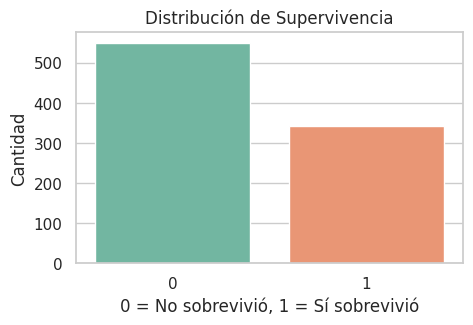

In [44]:
plt.figure(figsize=(5, 3))
ax = sns.countplot(x='Survived', hue='Survived', data=df, palette='Set2', legend= False)
plt.title('Distribución de Supervivencia')
plt.xlabel('0 = No sobrevivió, 1 = Sí sobrevivió')
plt.ylabel('Cantidad')
plt.show()

En esta gráfica básica podemos observar que la mayooría de los pasajeros no sobrevivieron

3.1.2. ¿Cómo se distribuyen las edades de los pasajero abordo?

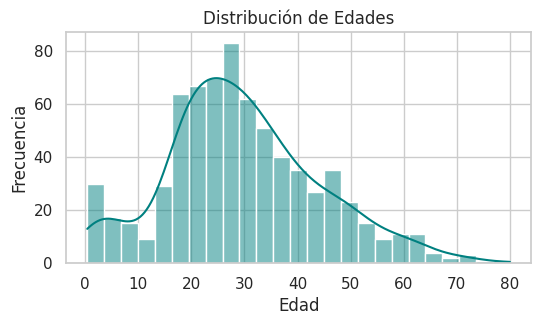

In [45]:
plt.figure(figsize=(6, 3))
sns.histplot(df['Age'].dropna(), bins=25, kde=True, color='teal')
plt.title('Distribución de Edades')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

Como analizamos en la actividad 2, comprobamos que la mayoría de los pasajeros eran adultos jovenes, sin embargo también vemos del lado izquierdo de la gráfica, el cual nos idncia que existían bebés y niños, tal como concluimos es nuestro análisis previo.

3.1.3. ¿Existen valores extremos en el costo del boleto?

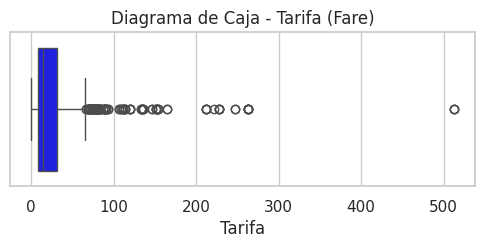

In [47]:
plt.figure(figsize=(6, 2))
sns.boxplot(x=df['Fare'], color='blue')
plt.title('Diagrama de Caja - Tarifa (Fare)')
plt.xlabel('Tarifa')
plt.show()

Como observamos la mayoría de los puntos se concentran en una sola región, sin embargo, hay puntos que se alejan demasiado, lo que nos indica que hay pasajeros que magaron precios extremadamente altos por el boleto, esto se confirma, ya que en nuestro análisis obtuvimos un valor máximo para la bariable "Fare" de más de 500. Esto nos ayuda para tomar en cuenta estos valores extremos al seguir con el desarrollo de nuestra práctica.

## 3.2. Análisis Bivariado